# Hotel Booking Cancellation Prediction System
## Exploratory Data Analysis (EDA)

---

## 1. Project Introduction

### Objective
The goal of this project is to develop a supervised machine learning system that predicts whether a hotel booking will be canceled or not.

This is a **Binary Classification** problem where the model will predict the booking status at the time the booking is registered.

### Project Workflow
The project follows a complete machine learning workflow:

1. Data Loading and Understanding
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Building
5. Model Evaluation
6. Model Saving
7. Streamlit Application Development
8. Testing and Deployment

In this notebook, we focus on understanding the dataset and exploring its characteristics before starting the preprocessing stage.

----
----
## 2. Environment Setup and Data Loading

### Objective
Prepare the notebook environment and load the dataset from the project's raw data directory.

### Steps
- Import the required libraries.
- Configure the project root directory to access reusable project modules.
- Import the data loading function from `src.data_loader`.
- Load the raw dataset into a Pandas DataFrame.


In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [86]:
from src.data_loader import load_data
df = load_data()

df.head()

,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,INN00001,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,INN00002,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,INN00003,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,INN00004,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,INN00005,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled



### Result
The dataset was successfully loaded from:

`data/raw/booking.csv`

The raw dataset is preserved separately from any future processed data to maintain a clear separation between original and modified data.

## 3. Initial Dataset Inspection

### Objective
Understand the general structure of the dataset and identify the available information.

### Steps
We performed an initial inspection to examine:

- Number of rows and columns.
- Column names.
- Data types.
- First and last records.
- Dataset information.
- Duplicate records.
- Missing values.

In [87]:
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")
print(f"Number of Duplicates: {df.duplicated().sum()}")
print(f"Number of Missing Values: {df.isna().sum().sum()}")
print("*"*50)
print(f"columns: {df.columns}")


Number of Rows: 36285
Number of Columns: 17
Number of Duplicates: 0
Number of Missing Values: 0
**************************************************
columns: Index(['Booking_ID', 'number of adults', 'number of children',
       'number of weekend nights', 'number of week nights', 'type of meal',
       'car parking space', 'room type', 'lead time', 'market segment type',
       'repeated', 'P-C', 'P-not-C', 'average price', 'special requests',
       'date of reservation', 'booking status'],
      dtype='str')


In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Booking_ID                36285 non-null  str    
 1   number of adults          36285 non-null  int64  
 2   number of children        36285 non-null  int64  
 3   number of weekend nights  36285 non-null  int64  
 4   number of week nights     36285 non-null  int64  
 5   type of meal              36285 non-null  str    
 6   car parking space         36285 non-null  int64  
 7   room type                 36285 non-null  str    
 8   lead time                 36285 non-null  int64  
 9   market segment type       36285 non-null  str    
 10  repeated                  36285 non-null  int64  
 11  P-C                       36285 non-null  int64  
 12  P-not-C                   36285 non-null  int64  
 13  average price             36285 non-null  float64
 14  special requests 

### Key Findings
- Total records: **36,285**
- Total columns: **17**
- Duplicate rows: **0**
- Initial missing values: **0**

The dataset contains numerical and categorical information about hotel bookings, along with the booking status as the target variable.

### Decision
No duplicate records or initial missing values were detected. However, further validation is still required to identify invalid values or inconsistencies that may not appear as missing values.

----

## 4. Understanding Features and Target Variable

### Objective
Identify the role of each column and understand the information available in the dataset.

### Steps
The columns were reviewed and grouped according to their purpose:

- Identifier: `Booking_ID`
- Numerical features: booking-related numerical information.
- Categorical features: meal type, room type, and market segment.
- Date feature: `date of reservation`
- Target variable: `booking status`

In [85]:
(df["booking status"].value_counts(normalize=True) * 100).round(2)

booking status
Not_Canceled    67.23
Canceled        32.77
Name: proportion, dtype: float64

In [17]:
df["booking status"].value_counts()

booking status
Not_Canceled    24396
Canceled        11889
Name: count, dtype: int64

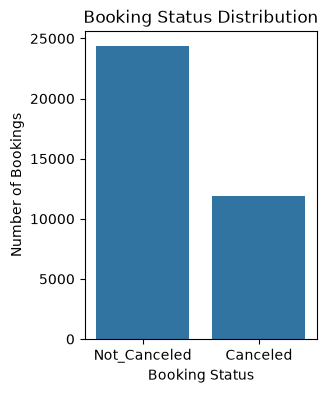

In [90]:
plt.figure(figsize=(3, 4))

sns.countplot(
    data=df,
    x="booking status"
)

plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")

plt.show()


### Target Variable Distribution

The target variable contains two classes:

- `Not_Canceled`
- `Canceled`

### Key Findings

| Booking Status | Number of Records | Percentage |
|---|---:|---:|
| Not_Canceled | 24,396 | 67.23% |
| Canceled | 11,889 | 32.77% |
| **Total** | **36,285** | **100%** |

The dataset contains more non-canceled bookings than canceled bookings.

### Decision
The target variable represents a binary classification problem with a moderate class imbalance. Therefore, model evaluation should consider multiple classification metrics rather than relying on accuracy alone.

----
----
## 5. Numerical Features Analysis

### Objective
Understand the statistical characteristics and distributions of numerical features.

### Steps
We used descriptive statistics to examine:

- Mean and standard deviation.
- Minimum and maximum values.
- Quartiles and median.
- Distribution ranges.

Boxplots were also used to visualize the distributions and identify potential outliers.

In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
number of adults,36285.0,1.844839,0.518813,0.0,2.0,2.00,2.0,4.0
number of children,36285.0,0.105360,0.402704,0.0,0.0,0.00,0.0,10.0
number of weekend nights,36285.0,0.810693,0.870590,0.0,0.0,1.00,2.0,7.0
number of week nights,36285.0,2.204602,1.410946,0.0,1.0,2.00,3.0,17.0
car parking space,36285.0,0.030977,0.173258,0.0,0.0,0.00,0.0,1.0
lead time,36285.0,85.239851,85.938796,0.0,17.0,57.00,126.0,443.0
repeated,36285.0,0.025630,0.158032,0.0,0.0,0.00,0.0,1.0
P-C,36285.0,0.023343,0.368281,0.0,0.0,0.00,0.0,13.0
P-not-C,36285.0,0.153369,1.753931,0.0,0.0,0.00,0.0,58.0
average price,36285.0,103.421636,35.086469,0.0,80.3,99.45,120.0,540.0


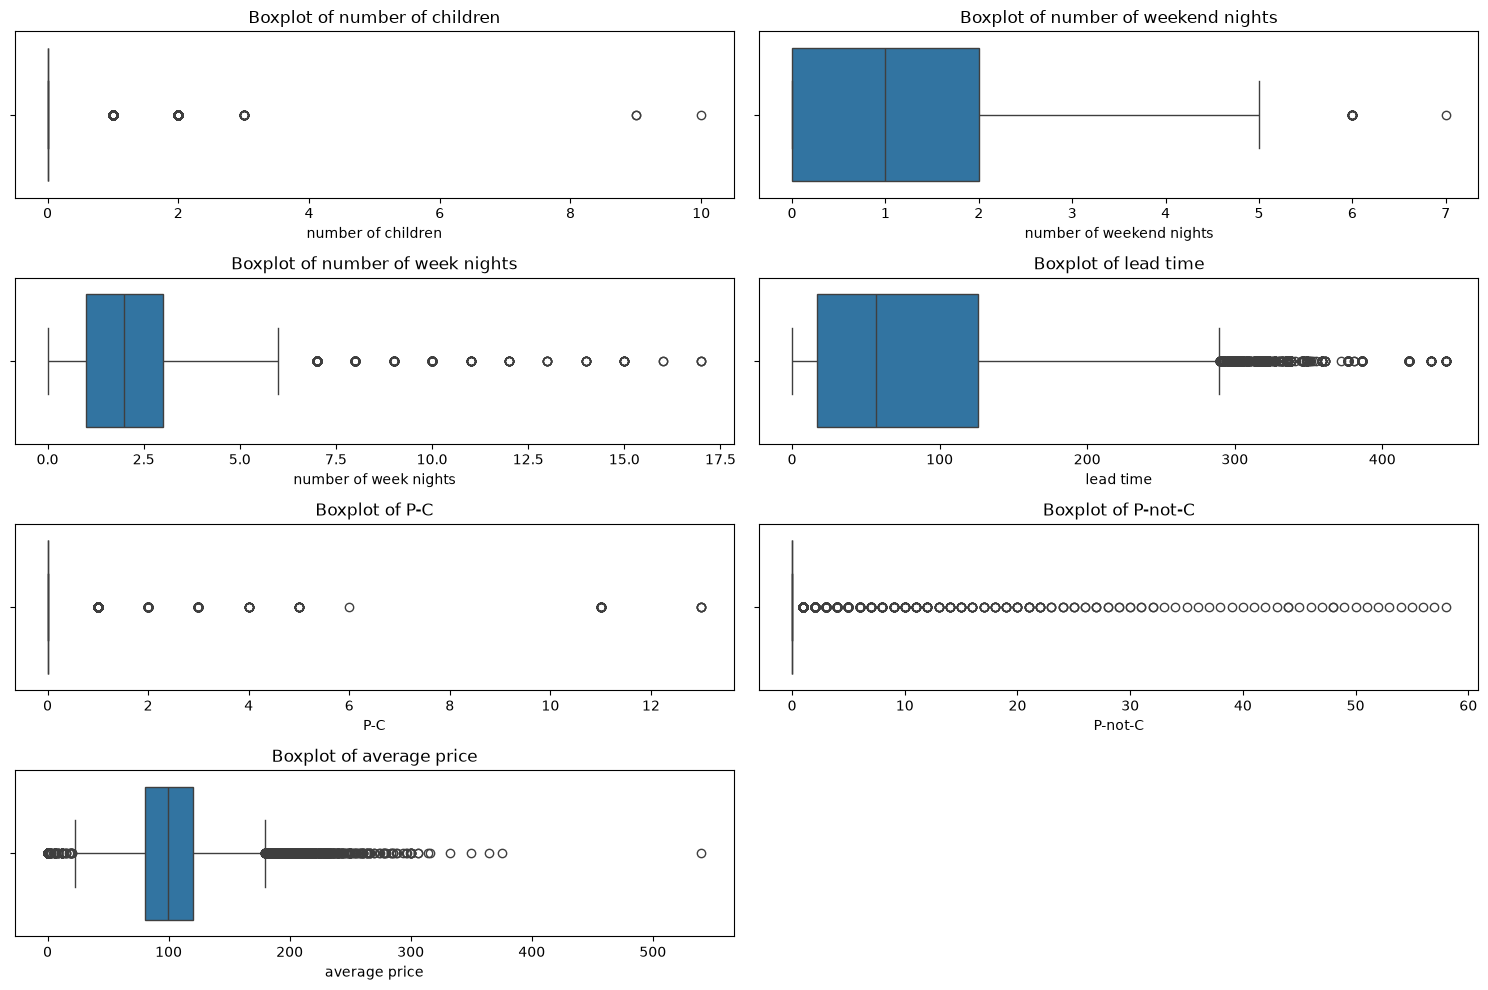

**************************************************


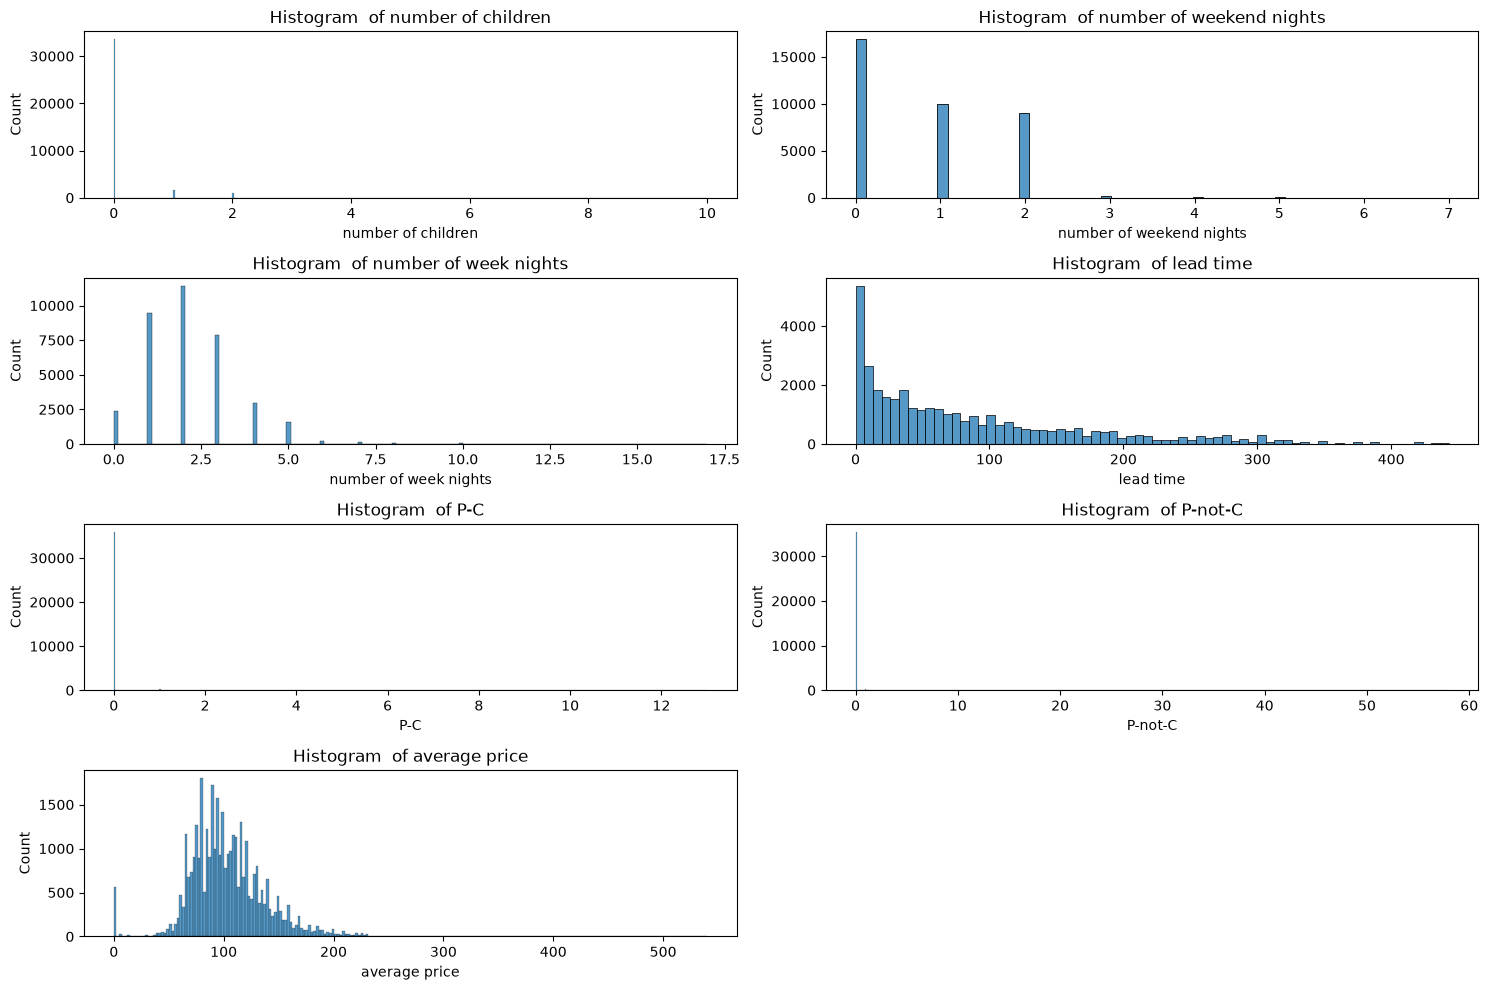

In [92]:

numerical_features = [
    "number of children",
    "number of weekend nights",
    "number of week nights",
    "lead time",
    "P-C",
    "P-not-C",
    "average price"
]



plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_features):
    plt.subplot(4, 2, i + 1)
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")


plt.tight_layout()
plt.show()

print("*" * 50)

plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_features):
    plt.subplot(4, 2, i + 1)
    sns.histplot(x=df[column])
    plt.title(f"Histogram  of {column}")


plt.tight_layout()
plt.show()

## 6. Data Validation: Zero and Negative Values

### Objective
Investigate zero and negative values in numerical features to distinguish valid observations from potential data quality issues.

### Steps
We checked the number of zero and negative values in selected numerical columns.

Special attention was given to:

- `number of adults`
- `number of children`
- `number of weekend nights`
- `number of week nights`
- `average price`

In [23]:
columns_to_check = [
    "number of adults",
    "number of children",
    "number of weekend nights",
    "number of week nights",
    "average price"
]

for column in columns_to_check:
    print(f"\n{column}")
    print("Zero values:", (df[column] == 0).sum())
    print("Negative values:", (df[column] < 0).sum())


number of adults
Zero values: 139
Negative values: 0

number of children
Zero values: 33583
Negative values: 0

number of weekend nights
Zero values: 16876
Negative values: 0

number of week nights
Zero values: 2387
Negative values: 0

average price
Zero values: 545
Negative values: 0


In [27]:
df[(df["number of children"] == 0) & (df["number of adults"]==0)].shape

(0, 17)

In [28]:
df[df["number of adults"] == 0].head(10)

,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
32,INN00033,0,2,0,3,Meal Plan 1,0,Room_Type 2,56,Online,0,0,0,82.44,1,12/7/2018,Not_Canceled
287,INN00288,0,2,2,2,Meal Plan 1,0,Room_Type 1,68,Online,0,0,0,108.38,1,4/24/2018,Canceled
653,INN00654,0,2,1,2,Meal Plan 1,0,Room_Type 2,78,Online,0,0,0,115.68,1,8/19/2018,Not_Canceled
937,INN00938,0,2,0,3,Meal Plan 1,0,Room_Type 2,40,Online,0,0,0,6.67,1,1/14/2018,Not_Canceled
954,INN00955,0,2,1,1,Meal Plan 1,0,Room_Type 2,92,Online,0,0,0,81.50,2,10/29/2018,Not_Canceled
1395,INN01396,0,1,2,4,Meal Plan 1,0,Room_Type 2,109,Online,0,0,0,73.74,1,4/1/2018,Not_Canceled
1660,INN01661,0,2,0,1,Meal Plan 1,0,Room_Type 1,130,Complementary,0,0,0,6.00,2,3/25/2018,Not_Canceled
2308,INN02309,0,2,0,1,Meal Plan 1,0,Room_Type 2,93,Online,0,0,0,109.83,1,8/13/2018,Not_Canceled
2331,INN02332,0,2,2,1,Meal Plan 1,0,Room_Type 2,34,Online,0,0,0,119.50,1,6/12/2018,Not_Canceled
2336,INN02337,0,2,1,3,Meal Plan 1,0,Room_Type 2,48,Online,0,0,0,6.00,1,10/19/2017,Not_Canceled


In [34]:
df[df["average price"] == 0]["booking status"].value_counts()

booking status
Not_Canceled    539
Canceled          6
Name: count, dtype: int64

In [31]:
df[df["average price"] == 0]["market segment type"].value_counts()

market segment type
Complementary    354
Online           191
Name: count, dtype: int64

In [32]:
df["market segment type"].value_counts()

market segment type
Online           23221
Offline          10531
Corporate         2017
Complementary      391
Aviation           125
Name: count, dtype: int64

In [38]:
df[(df["average price"] == 0)&(df["booking status"] == "Canceled")].head(10)

,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
2780,INN02781,1,0,0,1,Meal Plan 1,0,Room_Type 1,289,Online,0,0,0,0.0,0,10/17/2017,Canceled
13950,INN13951,1,0,0,2,Meal Plan 2,0,Room_Type 1,320,Online,0,0,0,0.0,0,8/18/2018,Canceled
14376,INN14377,2,0,0,0,Meal Plan 1,0,Room_Type 1,256,Online,0,0,0,0.0,0,9/14/2017,Canceled
17666,INN17667,1,0,1,3,Meal Plan 2,0,Room_Type 1,210,Online,0,0,0,0.0,0,10/8/2017,Canceled
22246,INN22247,2,0,0,0,Meal Plan 1,0,Room_Type 1,228,Online,0,0,0,0.0,0,6/4/2018,Canceled
29732,INN29733,1,0,0,3,Meal Plan 1,0,Room_Type 1,335,Online,0,0,0,0.0,0,10/13/2018,Canceled


### Key Findings
- Some records contain zero adults.
- No records contain children without adults.
- Zero values in the number of children and nights are valid in the context of hotel bookings.
- A number of records have an average price equal to zero.
- Many zero-price records are associated with the `Complementary` market segment.

### Decision
The investigated zero values were retained because they can represent valid booking scenarios.

We did not replace zero values with missing values or remove them without sufficient evidence.

----
----
## 7. Categorical Features Analysis

### Objective
Understand the distribution of categorical features and identify the most frequent categories.

### Steps
We examined the unique values and frequency counts of:

- `type of meal`
- `room type`
- `market segment type`

Bar charts were used to visualize the distribution of categories.

In [39]:
categorical_features = [
    "type of meal",
    "room type",
    "market segment type",
    "booking status"
]

for column in categorical_features:
    print(f"\n{column}")
    print(df[column].value_counts())
    print("-" * 40)


type of meal
type of meal
Meal Plan 1     27842
Not Selected     5132
Meal Plan 2      3306
Meal Plan 3         5
Name: count, dtype: int64
----------------------------------------

room type
room type
Room_Type 1    28138
Room_Type 4     6059
Room_Type 6      966
Room_Type 2      692
Room_Type 5      265
Room_Type 7      158
Room_Type 3        7
Name: count, dtype: int64
----------------------------------------

market segment type
market segment type
Online           23221
Offline          10531
Corporate         2017
Complementary      391
Aviation           125
Name: count, dtype: int64
----------------------------------------

booking status
booking status
Not_Canceled    24396
Canceled        11889
Name: count, dtype: int64
----------------------------------------


In [40]:
categorical_features = [
    "type of meal",
    "room type",
    "market segment type"
]

for column in categorical_features:

    print(f"\n{column}")

    result = pd.crosstab(
        df[column],
        df["booking status"],
        normalize="index"
    ) * 100

    print(result.round(2))

    print("-" * 50)


type of meal
booking status  Canceled  Not_Canceled
type of meal                          
Meal Plan 1        31.18         68.82
Meal Plan 2        45.58         54.42
Meal Plan 3        20.00         80.00
Not Selected       33.13         66.87
--------------------------------------------------

room type
booking status  Canceled  Not_Canceled
room type                             
Room_Type 1        32.26         67.74
Room_Type 2        32.95         67.05
Room_Type 3        28.57         71.43
Room_Type 4        34.15         65.85
Room_Type 5        27.17         72.83
Room_Type 6        42.03         57.97
Room_Type 7        22.78         77.22
--------------------------------------------------

market segment type
booking status       Canceled  Not_Canceled
market segment type                        
Aviation                29.60         70.40
Complementary            0.00        100.00
Corporate               10.91         89.09
Offline                 29.95         70.05
Onl

### Key Findings
- `Meal Plan 1` is the most frequent meal category.
- `Room_Type 1` is the most frequent room category.
- `Online` is the most frequent market segment.
- Some categories have very small numbers of observations, such as `Meal Plan 3` and `Room_Type 3`.

### Decision
The categorical values were reviewed, and no unexpected categories were identified.

Rare categories will be considered carefully during preprocessing and model development.

## 8. Date Feature Analysis

### Objective
Inspect the `date of reservation` column, understand its date range, and investigate invalid date values.

### Steps
- Inspect the original date format.
- Convert the column into a Pandas datetime format.
- Identify invalid date values.
- Examine the distribution of bookings across years and months.
- Compare cancellation distributions over time

In [43]:
print("data type",df["date of reservation"].dtype)
print("*" * 50)

print("head: \n", df["date of reservation"].head())
print("*" * 50)

print("min:", df["date of reservation"].min())
print("max:", df["date of reservation"].max())
print("*" * 50)

print("unique values:", df["date of reservation"].nunique())

data type str
**************************************************
head: 
 0    10/2/2015
1    11/6/2018
2    2/28/2018
3    5/20/2017
4    4/11/2018
Name: date of reservation, dtype: str
**************************************************
min: 1/1/2018
max: 9/9/2018
**************************************************
unique values: 553


In [51]:
df["date of reservation"] = pd.to_datetime(
    df["date of reservation"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("Data Type:")
print(df["date of reservation"].dtype)

print("\nMinimum Date:")
print(df["date of reservation"].min())

print("\nMaximum Date:")
print(df["date of reservation"].max())

print("\nNumber of Missing Values:")
print(df["date of reservation"].isna().sum())

print("\nNumber of Unique Dates:")
print(df["date of reservation"].nunique())

print("\nhead sorted dates: \n", df["date of reservation"].sort_values().head(10))

Data Type:
datetime64[us]

Minimum Date:
2015-10-02 00:00:00

Maximum Date:
2018-12-31 00:00:00

Number of Missing Values:
37

Number of Unique Dates:
552

head sorted dates: 
 0       2015-10-02
5       2016-09-13
3       2017-05-20
5455    2017-07-01
13727   2017-07-01
13907   2017-07-01
34751   2017-07-01
2005    2017-07-01
14409   2017-07-01
14889   2017-07-01
Name: date of reservation, dtype: datetime64[us]


In [ ]:
# Reload the original dataset
raw_df = load_data()

# Identify dates that could not be converted
parsed_dates = pd.to_datetime(
    raw_df["date of reservation"],
    format="%m/%d/%Y",
    errors="coerce"
)

invalid_dates = raw_df.loc[parsed_dates.isna(),"date of reservation"]

print("Number of Invalid Dates:", len(invalid_dates))

print("\nInvalid Date Values:")
print(invalid_dates.value_counts(dropna=False))

Number of Invalid Dates: 37

Invalid Date Values:
date of reservation
2018-2-29    37
Name: count, dtype: int64


In [ ]:
invalid_dates  # مفيش يوم 29 فبراير لأنها مش سنة كبيسة

2626     2018-2-29
3677     2018-2-29
5600     2018-2-29
6343     2018-2-29
7648     2018-2-29
8000     2018-2-29
8989     2018-2-29
9153     2018-2-29
9245     2018-2-29
9664     2018-2-29
9934     2018-2-29
10593    2018-2-29
10652    2018-2-29
10747    2018-2-29
11881    2018-2-29
13958    2018-2-29
14304    2018-2-29
15363    2018-2-29
15438    2018-2-29
17202    2018-2-29
18380    2018-2-29
18534    2018-2-29
18680    2018-2-29
19013    2018-2-29
20419    2018-2-29
21674    2018-2-29
21688    2018-2-29
26108    2018-2-29
27559    2018-2-29
27928    2018-2-29
30552    2018-2-29
30616    2018-2-29
30632    2018-2-29
30839    2018-2-29
32041    2018-2-29
34638    2018-2-29
35481    2018-2-29
Name: date of reservation, dtype: str

### Key Findings
- The date format is `%m/%d/%Y`.
- The valid date range extends from October 2015 to December 2018.
- There are 37 invalid date values.
- All invalid values correspond to `2018-2-29`, which is not a valid calendar date.
- The monthly cancellation distribution varies across the observed years.

### Decision
The 37 records were retained, and their invalid dates were converted to `NaT`.

We did not guess replacement dates.


In [54]:
# Extract Year and Month for EDA
date_analysis = pd.DataFrame({
    "Year": parsed_dates.dt.year,
    "Month": parsed_dates.dt.month,
    "Booking Status": raw_df["booking status"]
})

# Cancellation rate by year
yearly_cancellation = pd.crosstab(
    date_analysis["Year"],
    date_analysis["Booking Status"],
    normalize="index"
) * 100

print("Cancellation Distribution by Year:")
print(yearly_cancellation.round(2))

Cancellation Distribution by Year:
Booking Status  Canceled  Not_Canceled
Year                                  
2015.0              0.00        100.00
2016.0            100.00          0.00
2017.0             14.76         85.24
2018.0             36.73         63.27


In [55]:
yearly_summary = pd.crosstab(
    date_analysis["Year"],
    date_analysis["Booking Status"]
)

print(yearly_summary)

Booking Status  Canceled  Not_Canceled
Year                                  
2015.0                 0             1
2016.0                 1             0
2017.0               962          5554
2018.0             10919         18811


In [56]:
monthly_cancellation = pd.crosstab(
    date_analysis["Month"],
    date_analysis["Booking Status"],
    normalize="index"
) * 100

print("Cancellation Distribution by Month:")
print(monthly_cancellation.round(2))

Cancellation Distribution by Month:
Booking Status  Canceled  Not_Canceled
Month                                 
1.0                 2.37         97.63
2.0                25.42         74.58
3.0                29.69         70.31
4.0                36.39         63.61
5.0                36.51         63.49
6.0                40.31         59.69
7.0                44.98         55.02
8.0                39.02         60.98
9.0                33.37         66.63
10.0               35.34         64.66
11.0               29.35         70.65
12.0               13.30         86.70


In [57]:
monthly_summary = pd.crosstab(
    date_analysis["Month"],
    date_analysis["Booking Status"]
)

monthly_summary["Total Bookings"] = monthly_summary.sum(axis=1)

print(monthly_summary)

Booking Status  Canceled  Not_Canceled  Total Bookings
Month                                                 
1.0                   24           990            1014
2.0                  424          1244            1668
3.0                  700          1658            2358
4.0                  996          1741            2737
5.0                  949          1650            2599
6.0                 1291          1912            3203
7.0                 1314          1607            2921
8.0                 1488          2325            3813
9.0                 1539          3073            4612
10.0                1880          3440            5320
11.0                 875          2106            2981
12.0                 402          2620            3022


In [ ]:
year_month_analysis = date_analysis.groupby(["Year", "Month"]).agg(
    Total_Bookings=("Booking Status", "count"),
    Canceled_Bookings=("Booking Status",lambda x: (x == "Canceled").sum()
    )
)

year_month_analysis["Cancellation_Rate"] = (
    year_month_analysis["Canceled_Bookings"]
    / year_month_analysis["Total_Bookings"]
) * 100

print(year_month_analysis.round(2))

              Total_Bookings  Canceled_Bookings  Cancellation_Rate
Year   Month                                                      
2015.0 10.0                1                  0               0.00
2016.0 9.0                 1                  1             100.00
2017.0 5.0                 1                  1             100.00
       7.0               363                243              66.94
       8.0              1014                185              18.24
       9.0              1649                182              11.04
       10.0             1914                302              15.78
       11.0              647                 27               4.17
       12.0              928                 22               2.37
2018.0 1.0              1014                 24               2.37
       2.0              1668                424              25.42
       3.0              2358                700              29.69
       4.0              2737                996              3

**Important Note:** The exact meaning of `date of reservation` is not documented. We cannot confirm whether it represents the booking creation date or another date related to the reservation.

Therefore, this feature will not be used in model training unless its meaning and availability at prediction time can be verified.

## 9. Numerical Features vs. Target Analysis

### Objective
Explore the relationship between numerical features and the target variable to identify potentially useful predictors.

### Steps
We grouped the data by `booking status` and compared numerical feature statistics between canceled and non-canceled bookings.

We also examined cancellation rates across different values of selected numerical features.


In [59]:
lead_time_analysis = df.groupby("booking status")["lead time"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(lead_time_analysis.round(2))

                count    mean  median  min  max
booking status                                 
Canceled        11889  139.22   122.0    0  443
Not_Canceled    24396   58.93    39.0    0  386


In [60]:
previous_bookings_analysis = df.groupby("booking status")[
    ["P-C", "P-not-C"]
].agg(["mean", "median", "max"])

print(previous_bookings_analysis.round(2))

                 P-C            P-not-C           
                mean median max    mean median max
booking status                                    
Canceled        0.01    0.0  13    0.00    0.0  12
Not_Canceled    0.03    0.0  11    0.23    0.0  58


In [62]:
special_requests_analysis = pd.crosstab(
    df["special requests"],
    df["booking status"],
    normalize="index"
) * 100

print(special_requests_analysis.round(2))

print("*"*50)

special_requests_analysis_normal = pd.crosstab(
    df["special requests"],
    df["booking status"],
   )
print(special_requests_analysis_normal) 

booking status    Canceled  Not_Canceled
special requests                        
0                    43.21         56.79
1                    23.77         76.23
2                    14.60         85.40
3                     0.00        100.00
4                     0.00        100.00
5                     0.00        100.00
**************************************************
booking status    Canceled  Not_Canceled
special requests                        
0                     8547         11233
1                     2705          8674
2                      637          3727
3                        0           676
4                        0            78
5                        0             8


In [63]:
price_analysis = df.groupby("booking status")["average price"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(price_analysis.round(2))

                count    mean  median    std  min    max
booking status                                          
Canceled        11889  110.58   108.0  32.27  0.0  540.0
Not_Canceled    24396   99.93    95.0  35.87  0.0  375.5


### Key Findings
- Canceled bookings have a higher average `lead time` than non-canceled bookings.
- The average price is slightly higher for canceled bookings.
- Canceled bookings show some differences in the average number of adults and stay nights.
- Cancellation rates vary across the number of special requests.

### Decision
Some numerical features show potentially useful differences between the two target classes.

These observations are descriptive and do not establish causal relationships.

In [65]:
guests_stay_analysis = df.groupby("booking status")[
    [
        "number of adults",
        "number of children",
        "number of weekend nights",
        "number of week nights"
    ]
].agg(["mean", "median", "max"])

display(guests_stay_analysis.round(2))

number of adults            number of children             \
                           mean median max               mean median max   
booking status                                                             
Canceled                   1.91    2.0   4               0.12    0.0   9   
Not_Canceled               1.81    2.0   4               0.10    0.0  10   

               number of weekend nights            number of week nights  \
                                   mean median max                  mean   
booking status                                                             
Canceled                           0.89    1.0   7                  2.39   
Not_Canceled                       0.77    1.0   6                  2.11   

                           
               median max  
booking status             
Canceled          2.0  17  
Not_Canceled      2.0  17

## 10. Binary and Categorical Features vs. Target Analysis

### Objective
Investigate how booking cancellation rates vary across binary and categorical features.

### Steps
We used cross-tabulations and row-normalized percentages to compare the distribution of the target classes across feature categories.

The analysis included:

- `car parking space`
- `repeated`
- `type of meal`
- `room type`
- `market segment type`



car parking space
Percentages:


booking status,Canceled,Not_Canceled
car parking space,,
0,33.49,66.51
1,10.14,89.86



Counts:


booking status,Canceled,Not_Canceled
car parking space,,
0,11775,23386
1,114,1010


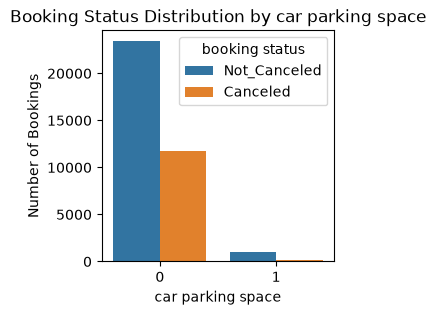

**************************************************

repeated
Percentages:


booking status,Canceled,Not_Canceled
repeated,,
0,33.58,66.42
1,1.72,98.28



Counts:


booking status,Canceled,Not_Canceled
repeated,,
0,11873,23482
1,16,914


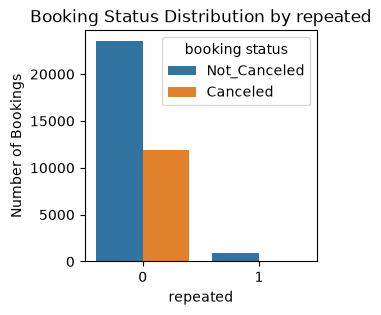

**************************************************


In [72]:
binary_features = ["car parking space", "repeated"]

for feature in binary_features:
    print(f"\n{feature}")

    analysis = pd.crosstab(
        df[feature],
        df["booking status"],
        normalize="index"
    ) * 100

    counts = pd.crosstab(
        df[feature],
        df["booking status"]
    )

    print("Percentages:")
    display(analysis.round(2))

    print("\nCounts:")
    display(counts)

    plt.figure(figsize=(3, 3))
    sns.countplot(
        data=df,
        x=feature,
        hue="booking status"
    )

    plt.title(f"Booking Status Distribution by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Bookings")

    plt.show()

    print("*"*50)

### Key Findings
- Bookings with a parking space show a lower cancellation rate in this dataset.
- Repeated customers show a substantially lower cancellation rate than non-repeated customers.
- Online bookings have a higher cancellation rate than the other major market segments.
- Cancellation rates vary across meal plans and room types.
- Some categories contain very few records, so their cancellation percentages should be interpreted cautiously.

### Decision
These features may provide useful information for predicting booking cancellations.

However, observed differences represent associations within this dataset and should not be interpreted as proof of causation.

-----
-----
## 11. Correlation Analysis

### Objective
Examine the correlations between numerical features and identify potentially strong relationships between predictors.

### Steps
- Calculate the Pearson correlation matrix for numerical features.
- Visualize the correlation matrix using a heatmap.
- Review the strongest correlations between numerical variables.

In [76]:
numerical_features = df.select_dtypes(include="number")

correlation_matrix = numerical_features.corr()

display(correlation_matrix.round(2))

,number of adults,number of children,number of weekend nights,number of week nights,car parking space,lead time,repeated,P-C,P-not-C,average price,special requests
number of adults,1.00,-0.02,0.10,0.11,0.01,0.10,-0.19,-0.05,-0.12,0.30,0.19
number of children,-0.02,1.00,0.03,0.02,0.03,-0.05,-0.04,-0.02,-0.02,0.34,0.12
number of weekend nights,0.10,0.03,1.00,0.18,-0.03,0.05,-0.07,-0.02,-0.03,-0.00,0.06
number of week nights,0.11,0.02,0.18,1.00,-0.05,0.15,-0.10,-0.03,-0.05,0.02,0.05
car parking space,0.01,0.03,-0.03,-0.05,1.00,-0.07,0.11,0.03,0.06,0.06,0.09
lead time,0.10,-0.05,0.05,0.15,-0.07,1.00,-0.14,-0.05,-0.08,-0.06,-0.10
repeated,-0.19,-0.04,-0.07,-0.10,0.11,-0.14,1.00,0.39,0.54,-0.17,-0.01
P-C,-0.05,-0.02,-0.02,-0.03,0.03,-0.05,0.39,1.00,0.47,-0.06,-0.00
P-not-C,-0.12,-0.02,-0.03,-0.05,0.06,-0.08,0.54,0.47,1.00,-0.11,0.03
average price,0.30,0.34,-0.00,0.02,0.06,-0.06,-0.17,-0.06,-0.11,1.00,0.18


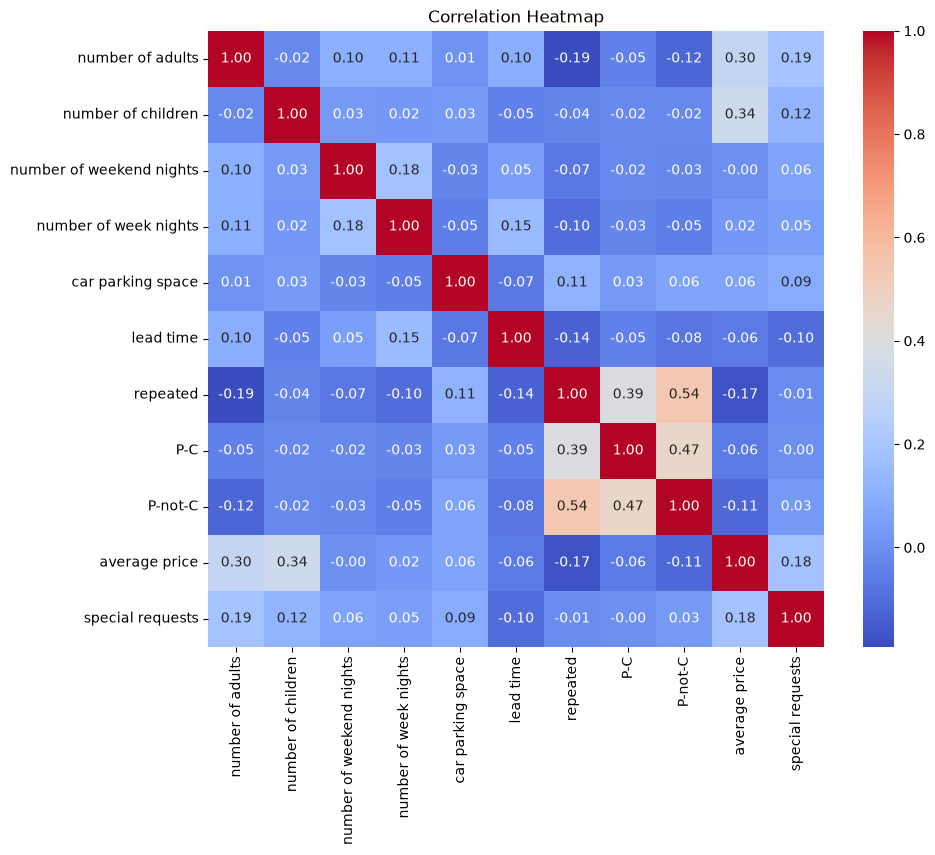

In [93]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True
)

plt.title("Correlation Heatmap")
plt.show()


### Key Findings
Some of the relatively stronger positive correlations include:

| Features | Correlation |
|---|---:|
| `repeated` and `P-not-C` | 0.54 |
| `P-C` and `P-not-C` | 0.47 |
| `repeated` and `P-C` | 0.39 |
| `number of adults` and `average price` | 0.30 |
| `number of children` and `average price` | 0.34 |

No extremely high correlations were identified among the numerical features.

### Decision
No feature was removed based solely on correlation analysis.

Correlation does not necessarily imply causation, and Pearson correlation does not capture every type of relationship between variables.

----
----
## 12. Final Feature Review and EDA Conclusion

### Objective
Finalize the initial feature selection and summarize the findings before moving to data preprocessing.


In [77]:
categorical_features = [
    "type of meal",
    "room type",
    "market segment type",
    "booking status"
]

binary_features = [
    "car parking space",
    "repeated"
]

for feature in binary_features + categorical_features:
    print(f"\n{feature}")
    print(df[feature].value_counts(dropna=False))
    print("-" * 50)


car parking space
car parking space
0    35161
1     1124
Name: count, dtype: int64
--------------------------------------------------

repeated
repeated
0    35355
1      930
Name: count, dtype: int64
--------------------------------------------------

type of meal
type of meal
Meal Plan 1     27842
Not Selected     5132
Meal Plan 2      3306
Meal Plan 3         5
Name: count, dtype: int64
--------------------------------------------------

room type
room type
Room_Type 1    28138
Room_Type 4     6059
Room_Type 6      966
Room_Type 2      692
Room_Type 5      265
Room_Type 7      158
Room_Type 3        7
Name: count, dtype: int64
--------------------------------------------------

market segment type
market segment type
Online           23221
Offline          10531
Corporate         2017
Complementary      391
Aviation           125
Name: count, dtype: int64
--------------------------------------------------

booking status
booking status
Not_Canceled    24396
Canceled        11889
N

In [78]:
# Features
X = df.drop(columns=[
    "Booking_ID",
    "date of reservation",
    "booking status"
])

# Target
y = df["booking status"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Features:
['number of adults', 'number of children', 'number of weekend nights', 'number of week nights', 'type of meal', 'car parking space', 'room type', 'lead time', 'market segment type', 'repeated', 'P-C', 'P-not-C', 'average price', 'special requests']

Target:
booking status

Features Shape: (36285, 14)
Target Shape: (36285,)


In [79]:
print(X.dtypes)

number of adults              int64
number of children            int64
number of weekend nights      int64
number of week nights         int64
type of meal                    str
car parking space             int64
room type                       str
lead time                     int64
market segment type             str
repeated                      int64
P-C                           int64
P-not-C                       int64
average price               float64
special requests              int64
dtype: object


In [80]:
# Numerical Features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical Features
categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Number of Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("Number of Categorical Features:", len(categorical_features))

Numerical Features: ['number of adults', 'number of children', 'number of weekend nights', 'number of week nights', 'car parking space', 'lead time', 'repeated', 'P-C', 'P-not-C', 'average price', 'special requests']
Number of Numerical Features: 11

Categorical Features: ['type of meal', 'room type', 'market segment type']
Number of Categorical Features: 3


### Feature Selection

The following columns were excluded:

- `Booking_ID`: Identifier column that does not represent a meaningful booking characteristic.
- `date of reservation`: Temporarily excluded because its exact meaning and availability at prediction time are unknown.

The target variable is:

- `booking status`

The remaining 14 columns were selected as candidate input features.

### Feature Types

**Numerical Features (11):**
- `number of adults`
- `number of children`
- `number of weekend nights`
- `number of week nights`
- `car parking space`
- `lead time`
- `repeated`
- `P-C`
- `P-not-C`
- `average price`
- `special requests`

**Categorical Features (3):**
- `type of meal`
- `room type`
- `market segment type`

### Additional Feature Information
- `car parking space` and `repeated` are binary numerical features.
- `P-C` and `P-not-C` represent the customer's booking history before the current booking.
- All selected candidate features are assumed to be available at booking time for this project.

### Final Dataset Structure

| Item | Value |
|---|---:|
| Number of Records | 36,285 |
| Number of Selected Features | 14 |
| Numerical Features | 11 |
| Categorical Features | 3 |
| Target Variable | `booking status` |

### EDA Conclusion

The exploratory data analysis helped us understand the dataset structure, identify potential data quality issues, examine feature distributions, and investigate relationships between input features and the target variable.

The selected features will be used as the initial input for the machine learning workflow.

Some limitations remain, particularly the undocumented meaning of the date column and the absence of an independent dataset description. These limitations have been recorded rather than resolved through unsupported assumptions.

### Next Step: Data Preprocessing

After completing the exploratory analysis, the next stage is **Data Preprocessing**.

In this stage, we will prepare the features for machine learning by performing the appropriate data splitting, encoding, scaling, and other necessary transformations while avoiding data leakage.